# Introduction to Linear Algebra and the world of probablitites

In this work-sheet, we shall do two activities. First of all we shall check the power of SVD. Then we shall check how may we generate data from an arbitrary distribution (given that we have the ability to generate data from a uniform distribution).

## Singular Value Decomposition
Lets load an image and try to do it's SVD.

Please note the way to access an image from your Google drive. Change the code accordingly (and load an image in your Google drive) to access to your own image!

Mark that we shall be using PIL's Image library, a useful set of powerful algorithms for image processing.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import time

from PIL import Image

In [2]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Lets load the image and convert that to a gray-scale version (so that we can treat it just like a 2D matrix). What will happen if its not gray-scale?

> <b>ANSWER</b>
>
> The image will be a 3D object, because apart from height and width it will have depth, which will consits of 3 values (for RGB), thus an error will be raised when trying to create a matrix from it.

Mark how we have used the command $matrix$ to generate a matrix from the image!

In [146]:
img = Image.open("/content/drive/My Drive/Machine Learning/Lab 1/ocean.jpg")
imggray = img.convert('L')

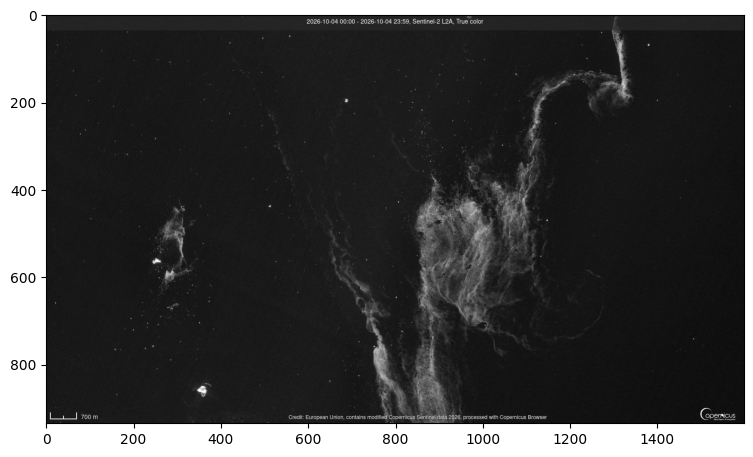

In [147]:
imgmat = np.array(list(imggray.getdata(band=0)), float)
imgmat.shape = (imggray.size[1], imggray.size[0])
imgmat = np.matrix(imgmat)
plt.figure(figsize=(9,6))
plt.imshow(imgmat, cmap='gray')

###SVD

We can directly use the $svd$ command from Numpy to operate SVD on the matrix.

Lets first check how the image will look if we only use a single vector to reconstruct the image.

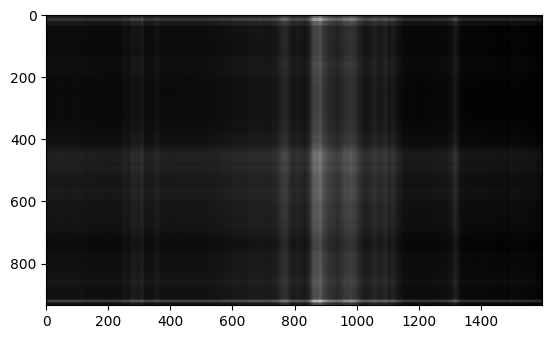

In [148]:
U, sigma, V = np.linalg.svd(imgmat)
reconstimg = np.matrix(U[:, :1]) * np.diag(sigma[:1]) * np.matrix(V[:1, :])
plt.imshow(reconstimg, cmap='gray');


Now lets check how does the sigma vector look like.

What do you observe? How many vecotrs can we use to get a decent reconstruction of the image?
What will happen if we omit the first 1-2 vectors (corresponding to the largest eigen values)?

> <b>ANSWER</b>
>
> - A plot with very high values at the beginning with a sudden drop right after, after wich values stay very low. The first values are highest because they correspond to the most impactful eigenvalues, capturing the most prominent features of the image.
> - Depends on the image and the needed level of detail for it to become recognisable.
> - The constrast of the image quickly decreases and details start to blend in with each other, because the skipped eigenvalues are the ones containing the greatest amount of information.

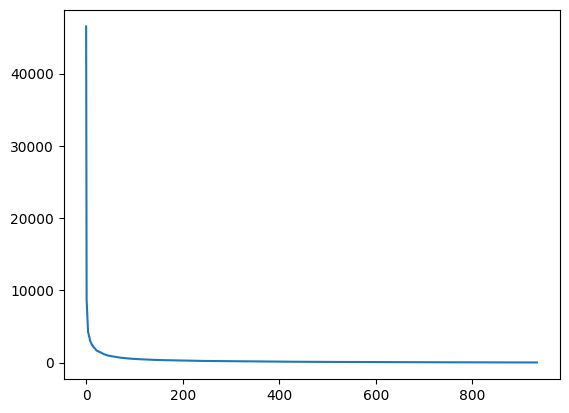

In [149]:
U.shape
sigma.shape
plt.plot(sigma)

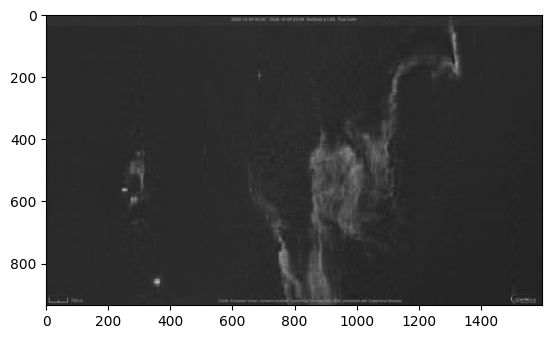

In [163]:
i = 40
j = 0
reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])
plt.imshow(reconstimg, cmap='gray');

> <b>ANSWER</b>
> 1. Using `forest.jpg` with 1 eigenvalue, the output is the same as with the provided 1 vector example. Increasing the eigenvalue amount outputs noisy images that progressively reveal the more prominent features. At around 14 eigenvalues the image is barely recognisable as terrain but no particular details can be distinguished. Around 30 eigenvalues the image is discernible but at a very low quality. Descent outputs start at around 65 eigenvalues.
> 2. No, because the biggest eigenvalues carry the greatest amount of information, with every next eigenvalue containing exponantially less. That is why generating the image with eigenvvalues from 10th to 70th creates blured grey noise with some noticible details like roads or characteristic terrain.
> 3.
> - Testing the code on `city.jpg`, it proved to be much harder to recognise at low eigenvalue amount, only becoming such at 30 eigenvalues. At 80, most structures were blending with each other, only becoming distinguishable at a reasonable level at around 130-140 eigenvalues. This is the result of the high amount of minute structure details present in urban environments
> - 1 vector representation of `desert.jpg` mostly consisted of similarly bright pixels. The most distinguishable part of the image started being noticeable at 12 eigenvalues and quickly became recognisable. Due to the low amount of varried features, the image is decently readable at 45-50 eigenvalues.
> - Inversely to the previous example, the 1 vector representation of `ocean.jpg` is dominated by dark pixels. Because of the low amount of differing structures, they become distinguishable at around 10 eigenvalues, with a decent visibility being achieved at 40.